# Intraday Momentum in SPY

*An Alpaca replication and extension of Zarattini, Aziz and Barbon*

## Abstract

This study compares intraday trend-following rules that trade when SPY moves outside a time-varying noise area. The experiments add a tighter stop, volatility-targeted sizing, and two entry filters. The historical sample spans 2019–2025, with 2023–2025 held out. All strategies are evaluated after trading costs.

[Reference paper](../ssrn-4824172-2.pdf) · [Case study](../case_study_intraday-1.pdf)

## 1. Introduction

An unusually large move away from the open may signal a persistent imbalance. If information or institutional orders take time to reach the market, prices can continue in the same direction. Range-bound sessions and abrupt reversals are the principal risks.

## 2. Data

The historical run uses split-adjusted Alpaca SIP minute bars in US dollars. NYSE regular hours define the session, including early closes. Missing minutes remain missing. A decision needs both its signal bar and its execution bar. An incomplete efficiency window blocks that entry. Sessions without an opening or closing bar are excluded, and the intraday strategies stay flat if the previous close is unavailable.

In [1]:
%matplotlib inline

from dataclasses import asdict
from datetime import date
from math import prod
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Markdown, display

root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "backtest.py").is_file()),
    None,
)
if root is None:
    raise RuntimeError("Open the notebook from this repository.")
sys.path.insert(0, str(root))

from src.backtest import BUY_AND_HOLD, EFFICIENCY_FILTERED, VOLATILITY_TARGETED, Costs, run_backtest
from src.demo import synthetic_sessions
from src.market_data import read_sessions
from src.paper_figures import (
    case_sessions, commission_figure, dollar_equity_figure, examples_figure, noise_figure,
)
from src.reporting import comparison_figure, summarize

DATA_MODE = "alpaca"  # "synthetic" or "alpaca"
DATA_PATH = root / "data" / "spy.csv"
SYNTHETIC_SEED = 42
COSTS = Costs(commission=0.0035, slippage=0.01)

BASELINE = "Opposite band"
VWAP = "Band + VWAP"
CONFIRMED = "Confirmed breakout"
PAPER_STRATEGIES = (BASELINE, VWAP, VOLATILITY_TARGETED, BUY_AND_HOLD)
ALL_STRATEGIES = (*PAPER_STRATEGIES[:-1], CONFIRMED, EFFICIENCY_FILTERED, BUY_AND_HOLD)

In [2]:
data_gaps = []
if DATA_MODE == "alpaca":
    start, end, test_start = date(2019, 1, 1), date(2025, 12, 31), date(2023, 1, 1)
    long_day, short_day, reversal_day = (date(2022, 1, 31), date(2022, 4, 29), date(2022, 1, 20))
    data_label = "Alpaca SIP · SPY"
elif DATA_MODE == "synthetic":
    start, end, test_start = date(2024, 1, 2), date(2024, 6, 28), date(2024, 4, 1)
    long_day, short_day, reversal_day = (date(2024, 2, 12), date(2024, 3, 12), date(2024, 4, 10))
    data_label = f"Synthetic demonstration · seed {SYNTHETIC_SEED}"
else:
    raise ValueError("Set DATA_MODE to 'synthetic' or 'alpaca'.")

def input_sessions(*, gaps=None):
    if DATA_MODE == "alpaca":
        return read_sessions(DATA_PATH, start, end, gaps=[] if gaps is None else gaps)
    return synthetic_sessions(start, end, seed=SYNTHETIC_SEED)

results = run_backtest(input_sessions(gaps=data_gaps), test_start, COSTS)
cases = case_sessions(input_sessions(), {long_day, short_day, reversal_day})
daily = pd.DataFrame(asdict(row) for row in results)
summary = summarize(results)
performance = pd.DataFrame(asdict(row) for row in summary)
coverage = daily.groupby("split", sort=False)["date"].agg(
    first_session="min", last_session="max", sessions="nunique"
)
display(Markdown(f"**{data_label}**"))
display(coverage)
if data_gaps:
    display(pd.DataFrame({
        "Session": gap.date,
        "Missing minutes": len(gap.missing_minutes),
        "First missing (NY)": gap.missing_minutes[0].strftime("%H:%M"),
        "Last missing (NY)": gap.missing_minutes[-1].strftime("%H:%M"),
        "Session excluded": gap.excluded,
    } for gap in data_gaps))

**Alpaca SIP · SPY**

,first_session,last_session,sessions
split,,,
train,2019-01-24,2022-12-30,992
test,2023-01-03,2025-12-31,752


,Session,Missing minutes,First missing (NY),Last missing (NY),Session excluded
0,2019-08-12,30,15:29,15:59,True
1,2020-03-09,14,09:35,09:48,False
2,2020-03-12,14,09:36,09:49,False
3,2020-03-16,14,09:31,09:44,False
4,2020-03-18,14,12:57,13:10,False
5,2021-05-05,5,11:27,11:31,False
6,2023-06-05,4,09:52,09:55,False


## 3. Strategy description

### 3.1 Noise area

At minute $m$, let $O_t$ be today’s open and $C_{t-1}$ the previous regular-session close. The noise statistic $s_{t,m}$ is the mean absolute move from the open at that minute over the prior 14 observed sessions for the slot.

$$
U_{t,m}=\max(O_t,C_{t-1})(1+s_{t,m}), \qquad
L_{t,m}=\min(O_t,C_{t-1})(1-s_{t,m}).
$$

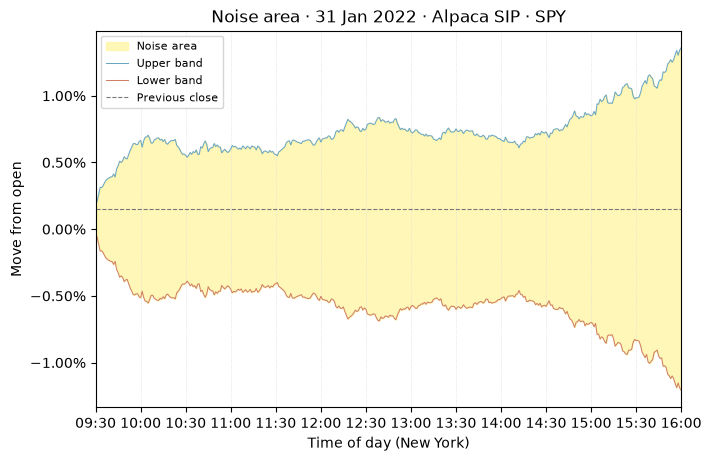

In [3]:
noise_figure(cases[long_day], f"Noise area · {long_day:%d %b %Y} · {data_label}")

**Figure 1.** The shaded region shows the gap-adjusted noise area. The upper and lower boundaries mark where price movement becomes unusual for that time of day.

### 3.2 Opposite-band strategy

At each half-hour check, a completed minute above the upper band triggers a long entry and one below the lower band triggers a short entry. The opposite band is the stop and reversal threshold. A fill uses the next bar’s open. A closing order flattens the position at the final regular-session bar’s close.

$$
Q_t=\left\lfloor\frac{\mathrm{Equity}_{t-1}}{O_t}\right\rfloor .
$$

Initial capital is USD 100,000. Each share incurs USD 0.0035 in commission and USD 0.01 in slippage per side. Shaded bands are drawn at minute resolution for illustration. Actual decisions remain on the half-hour grid.

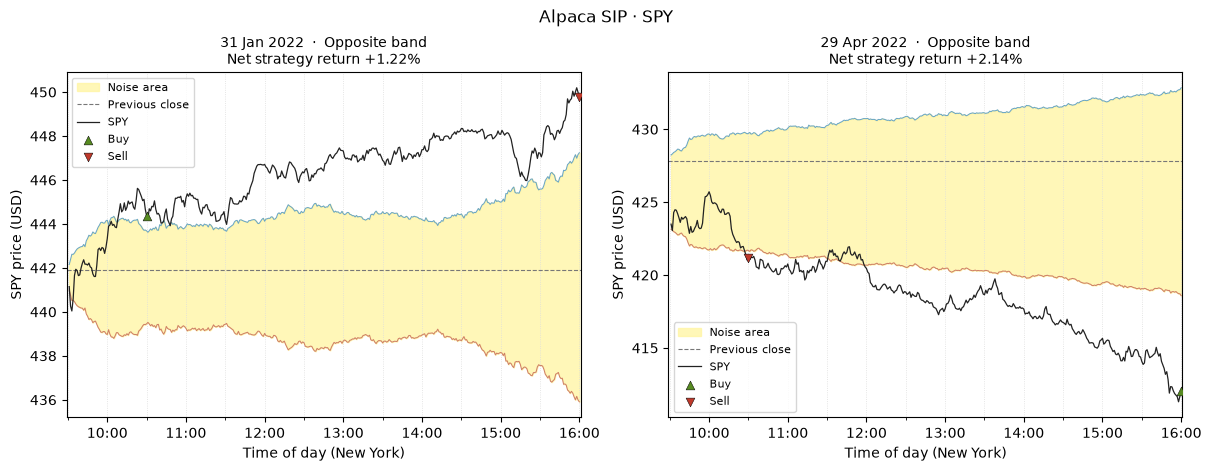

In [4]:
examples_figure(cases, results, [(long_day, BASELINE), (short_day, BASELINE)], COSTS, data_label)

**Figure 2.** Two sessions on the paper’s example dates in historical mode. Upward and downward triangles mark simulated buy and sell orders, including end-of-session exits. The daily strategy returns above the panels are net of costs.

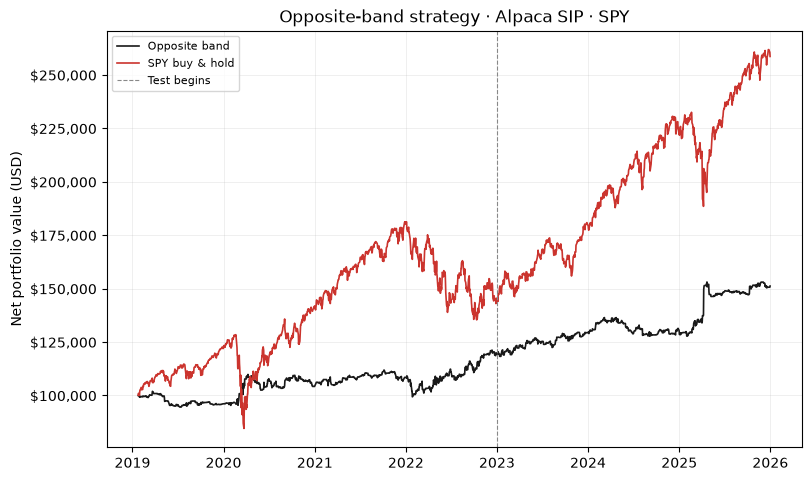

In [5]:
dollar_equity_figure(results, (BASELINE, BUY_AND_HOLD), f"Opposite-band strategy · {data_label}")

**Figure 3.** Dollar equity for the opposite-band strategy and price-only SPY buy-and-hold. The dashed line marks the start of the test period.

### 3.3 Tighter stops

The strategy can give back an early gain when price reverses within the noise area. The tighter stop combines the current band with regular-session VWAP.

$$
\mathrm{LongStop}_{t,m}=\max(U_{t,m},\mathrm{VWAP}_{t,m}),\qquad
\mathrm{ShortStop}_{t,m}=\min(L_{t,m},\mathrm{VWAP}_{t,m}).
$$

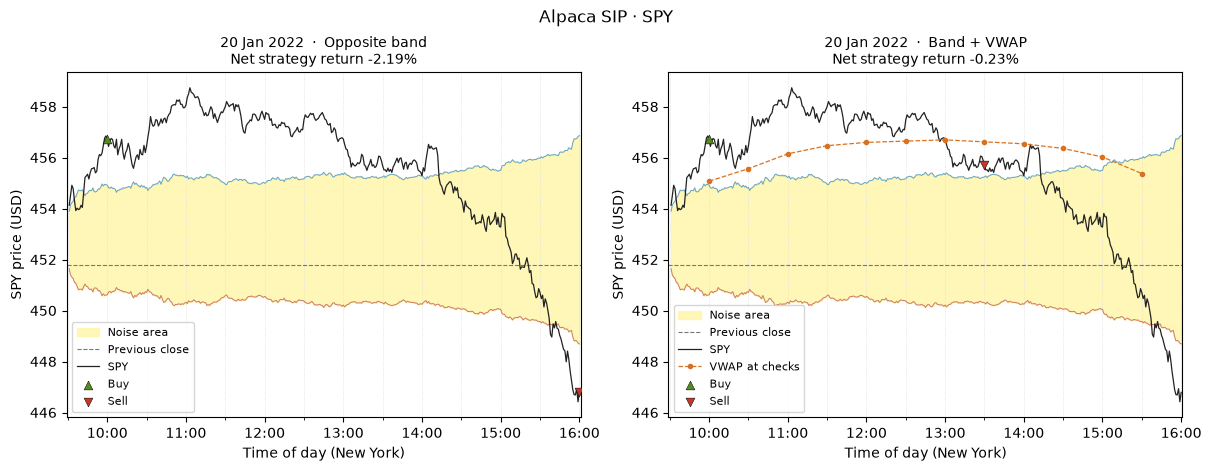

In [6]:
examples_figure(cases, results, [(reversal_day, BASELINE), (reversal_day, VWAP)], COSTS, data_label)

**Figure 4.** The opposite-band and band-plus-VWAP strategies on the same reversal session. The orange dashed line shows VWAP at decision times. The panels isolate the effect of changing the stop.

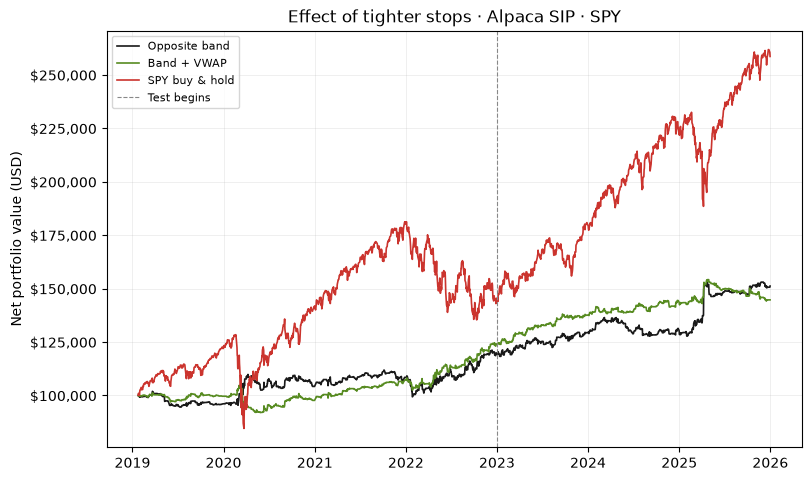

In [7]:
dollar_equity_figure(results, (BASELINE, VWAP, BUY_AND_HOLD), f"Effect of tighter stops · {data_label}")

**Figure 5.** Cumulative comparison of the two fixed-size momentum variants against the same benchmark.

### 3.4 Volatility-targeted sizing

The fixed-size VWAP strategy is then scaled by $\min(4, 0.02/\widehat\sigma_t)$, where $\widehat\sigma_t$ is the sample volatility of the last 14 usable close-to-close returns. The common warm-up supplies these returns before any strategy is evaluated.

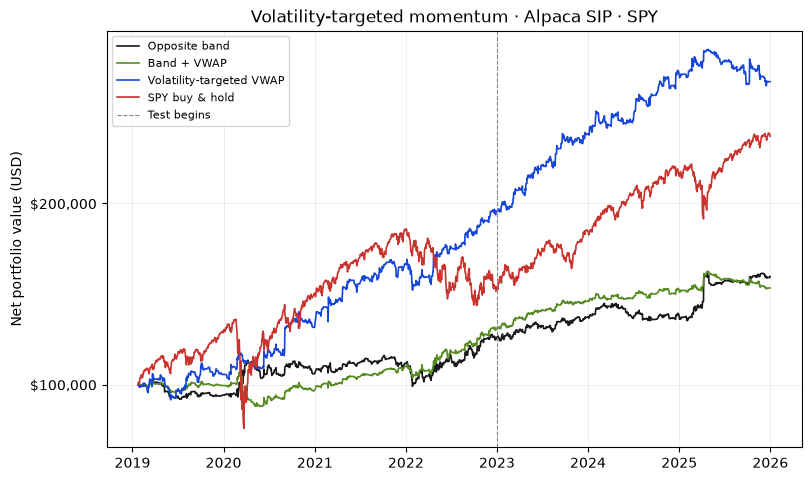

In [8]:
dollar_equity_figure(
    results, PAPER_STRATEGIES, f"Volatility-targeted momentum · {data_label}", log_scale=True
)

**Figure 6.** Net dollar equity on a logarithmic scale, with the volatility-targeted variant in blue.

### 3.5 Performance statistics

The tables follow the paper’s strategy, stop and size columns. Total return compounds within each sample. Annualized return and volatility use 252 trading sessions, Sharpe assumes a zero cash rate, hit ratio is the fraction of nonzero daily returns that are positive, and maximum drawdown is shown as a positive loss from the running peak within the sample. The SPY comparator is price-only and holds its position across the train/test boundary. Alpha and beta are descriptive estimates from a regression on aligned daily SPY returns. Alpha is the daily intercept multiplied by 252.

In [9]:
stops = {
    BASELINE: "Opposite band", VWAP: "Band + VWAP", VOLATILITY_TARGETED: "Band + VWAP",
    CONFIRMED: "Band + VWAP", EFFICIENCY_FILTERED: "Band + VWAP", BUY_AND_HOLD: "—",
}

def paper_table(split, strategies, caption):
    rows = []
    paired_returns = daily.loc[daily["split"].eq(split)].pivot(
        index="date", columns="strategy", values="net_return"
    )
    market = paired_returns[BUY_AND_HOLD]
    market_variance = market.var()
    for strategy in strategies:
        stats = performance.loc[
            performance["split"].eq(split) & performance["strategy"].eq(strategy)
        ].iloc[0]
        returns = paired_returns[strategy]
        beta = returns.cov(market) / market_variance if market_variance and strategy != BUY_AND_HOLD else None
        alpha = 252 * (returns.mean() - beta * market.mean()) if beta is not None else None
        active = returns[returns.ne(0)]
        rows.append({
            "Strategy": strategy, "Stop": stops[strategy],
            "Size": "Vol. target" if strategy == VOLATILITY_TARGETED else "100%",
            "Total return": prod(1 + returns) - 1,
            "Ann. return": stats["annualized_return"], "Vol.": stats["annualized_volatility"],
            "Sharpe": stats["sharpe"], "Hit ratio": active.gt(0).mean(),
            "Max. drawdown": -stats["max_drawdown"], "Alpha": alpha, "Beta": beta,
        })
    table = pd.DataFrame(rows)
    percentages = ["Total return", "Ann. return", "Vol.", "Hit ratio", "Max. drawdown", "Alpha"]
    return (
        table.style.hide(axis="index").set_caption(caption)
        .format({**dict.fromkeys(percentages, "{:.2%}"), "Sharpe": "{:.2f}", "Beta": "{:.2f}"}, na_rep="—")
        .set_table_styles([
            {"selector": "", "props": "border-collapse:collapse; border-top:2px solid #333; border-bottom:2px solid #333; font-family:serif"},
            {"selector": "caption", "props": "caption-side:top; text-align:left; font-weight:bold; padding:6px 0"},
            {"selector": "thead", "props": "border-bottom:1px solid #333"},
            {"selector": "th, td", "props": "padding:4px 8px; white-space:nowrap"},
        ])
        .set_properties(subset=["Strategy", "Stop", "Size"], **{"text-align": "left"})
    )

display(paper_table("train", PAPER_STRATEGIES, "Table 1. Paper variants in the development sample"))
display(paper_table("test", ALL_STRATEGIES, "Table 2. Strategy comparison in the held-out sample"))

Strategy,Stop,Size,Total return,Ann. return,Vol.,Sharpe,Hit ratio,Max. drawdown,Alpha,Beta
Opposite band,Opposite band,100%,19.93%,4.73%,10.14%,0.51,55.42%,11.17%,5.31%,-0.01
Band + VWAP,Band + VWAP,100%,24.13%,5.64%,7.73%,0.75,45.10%,12.16%,5.87%,-0.01
Volatility-targeted VWAP,Band + VWAP,Vol. target,94.32%,18.38%,14.18%,1.26,45.10%,11.07%,18.50%,-0.05
SPY buy & hold,—,100%,45.18%,9.93%,22.80%,0.53,54.49%,34.17%,—,—


Strategy,Stop,Size,Total return,Ann. return,Vol.,Sharpe,Hit ratio,Max. drawdown,Alpha,Beta
Opposite band,Opposite band,100%,26.08%,8.08%,8.55%,0.95,57.55%,6.41%,6.38%,0.09
Band + VWAP,Band + VWAP,100%,16.60%,5.28%,5.65%,0.94,47.05%,6.52%,5.20%,0.01
Volatility-targeted VWAP,Band + VWAP,Vol. target,64.03%,18.04%,14.30%,1.23,47.05%,12.94%,18.75%,-0.06
Confirmed breakout,Band + VWAP,100%,6.66%,2.18%,4.32%,0.52,45.56%,4.96%,2.57%,-0.02
Efficient breakout,Band + VWAP,100%,11.95%,3.85%,4.78%,0.82,45.11%,3.10%,3.73%,0.01
SPY buy & hold,—,100%,78.16%,21.35%,14.98%,1.37,57.39%,18.93%,—,—


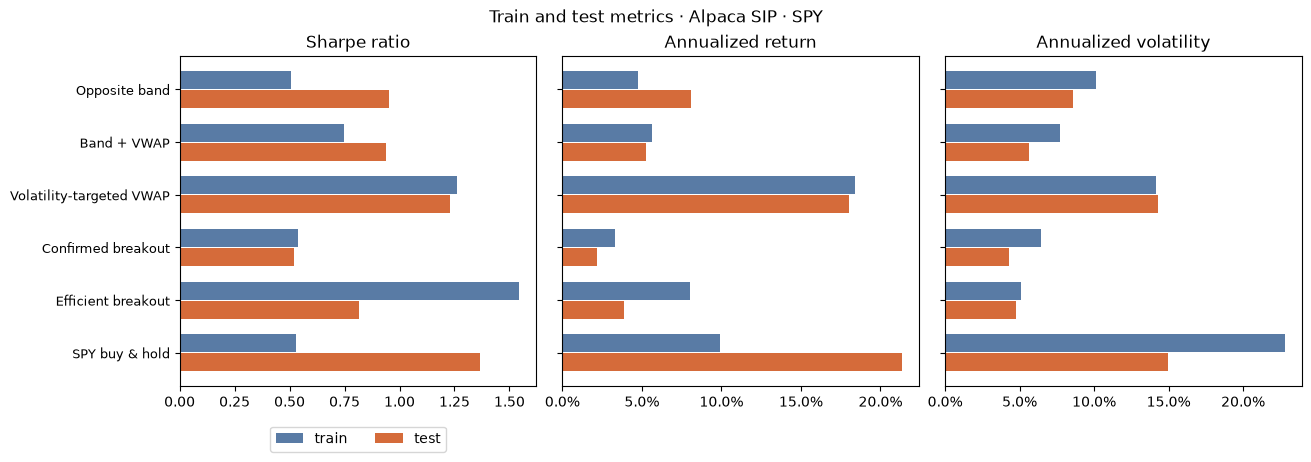

In [10]:
comparison_figure(summary, f"Train and test metrics · {data_label}")

**Figure 7.** Sharpe ratio, annualized return and annualized volatility by split, as required by the case study.

## 4. Further investigation

### 4.1 Impact of commissions

The volatility-targeted strategy is rerun from the initial capital at each commission rate. Slippage is held fixed, and whole-share positions are recalculated from each run’s equity. The chart shows total return in the held-out period. This is a cost sensitivity check with fixed strategy rules.

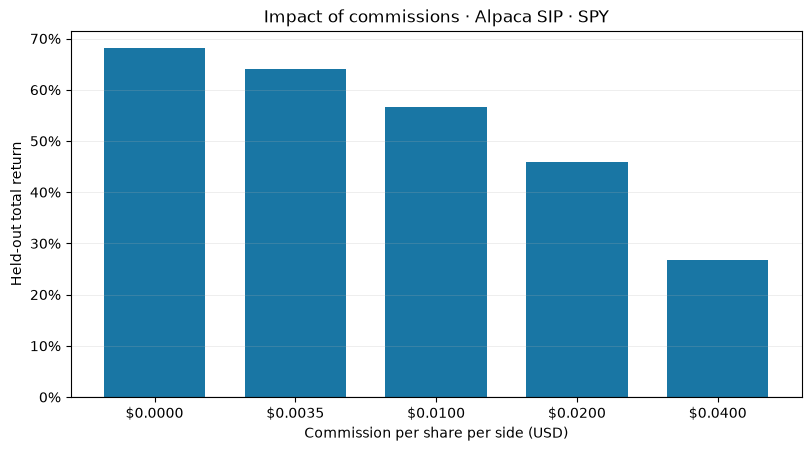

In [11]:
commissions = [0.0, COSTS.commission, 0.01, 0.02, 0.04]
sensitivity = []
for commission in commissions:
    scenario = results if commission == COSTS.commission else run_backtest(
        input_sessions(), test_start, Costs(commission=commission, slippage=COSTS.slippage)
    )
    sensitivity.append(prod(
        1 + row.net_return for row in scenario
        if row.split == "test" and row.strategy == VOLATILITY_TARGETED
    ) - 1)
commission_figure(commissions, sensitivity, f"Impact of commissions · {data_label}")

**Figure 8.** Commission sensitivity for the volatility-targeted strategy. Slippage stays at USD 0.01 per share per side.

### 4.2 Original entry variation

**Efficient Breakout** requires signed net displacement in the breakout direction to be at least 35% of all absolute price changes in the preceding 30 completed minutes. Sizing and exits match fixed-size Band + VWAP. The rule can ignore noisy breakouts without forcing a clean breakout to wait for another half-hour check. It can also discard valid breakouts after a sharp reversal. The threshold was fixed before the historical run.

**Confirmed Breakout** provides a second comparison. It requires two consecutive same-side checks and can miss momentum immediately following the first breakout.

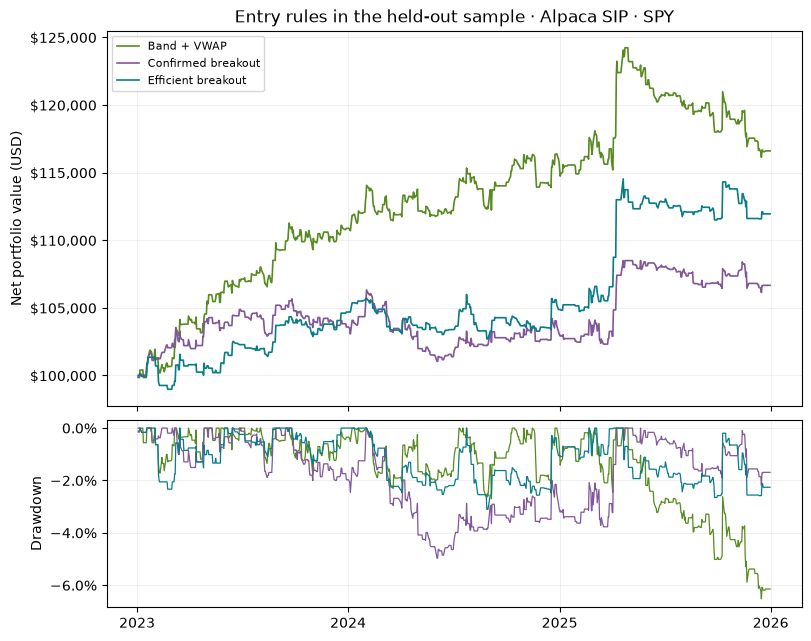

In [12]:
dollar_equity_figure(
    results, (VWAP, CONFIRMED, EFFICIENCY_FILTERED),
    f"Entry rules in the held-out sample · {data_label}", test_only=True, drawdown=True,
)

**Figure 9.** Held-out equity and drawdown for the two entry variations and their fixed-size VWAP comparator. Each series is rebased to USD 100,000 at the start of the test period.

In [13]:
paired = daily.loc[daily["split"].eq("test")].pivot(
    index="date", columns="strategy", values="net_return"
)
delta_bps = 10_000 * (paired[EFFICIENCY_FILTERED] - paired[VWAP]).mean()
test_metrics = performance.loc[performance["split"].eq("test")].set_index("strategy")
numeric = test_metrics.drop(columns="split").astype(float)
changes = numeric.loc[EFFICIENCY_FILTERED] - numeric.loc[VWAP]
deltas = pd.DataFrame({
    "Measure": ["Average daily net return", "Sharpe", "Maximum drawdown depth",
                "Traded shares", "Modeled execution cost"],
    "Change": [f"{delta_bps:+.2f} bp", f"{changes['sharpe']:+.2f}",
               f"{-100 * changes['max_drawdown']:+.2f} pp",
               f"{changes['traded_shares']:+,.0f}", f"{changes['total_cost']:+,.2f} USD"],
})
display(deltas.style.hide(axis="index").set_caption(
    f"Table 3. Efficient Breakout minus Band + VWAP across {len(paired)} held-out sessions"
))

Measure,Change
Average daily net return,-0.56 bp
Sharpe,-0.12
Maximum drawdown depth,-3.42 pp
Traded shares,"-206,426"
Modeled execution cost,"-2,786.75 USD"


## 5. Discussion and limitations

Compare Sharpe with drawdown, turnover and the number of sessions. Dollar costs also reflect differences in compounded capital. Quiet markets can produce repeated false breakouts, while rapid reversals can move through a stop before the next check.

This replication uses Alpaca data, next-bar open fills and a different sample. It excludes broker minimums, borrow fees, partial fills, dividends, and size-dependent market impact. The paper’s VIX and dealer-gamma studies require additional datasets. Synthetic mode is a seeded demonstration of the notebook workflow.

In [14]:
intraday = test_metrics.drop(index=BUY_AND_HOLD)
best = intraday["sharpe"].idxmax()
best_row = intraday.loc[best]
efficient = test_metrics.loc[EFFICIENCY_FILTERED]
reference = test_metrics.loc[VWAP]
display(Markdown(
    f"**{data_label}.** {best} had the highest held-out Sharpe among the intraday variants "
    f"at {best_row['sharpe']:.2f} and returned {best_row['annualized_return']:.2%} annualized. "
    f"Efficient Breakout had a Sharpe of {efficient['sharpe']:.2f} versus {reference['sharpe']:.2f} "
    f"for fixed-size Band + VWAP. Their maximum drawdowns were "
    f"{-efficient['max_drawdown']:.2%} and {-reference['max_drawdown']:.2%}, respectively."
))

**Alpaca SIP · SPY.** Volatility-targeted VWAP had the highest held-out Sharpe among the intraday variants at 1.23 and returned 18.04% annualized. Efficient Breakout had a Sharpe of 0.82 versus 0.94 for fixed-size Band + VWAP. Their maximum drawdowns were 3.10% and 6.52%, respectively.